In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('cardekho_data.csv')
df.columns = df.columns.str.strip()

In [ ]:
df.head()

---

## 4. Data Preprocessing

### 4.1 Checking and Handle Missing Value and Data Duplicated

In [ ]:
print("--- Missing Value ---")
print(df.isnull().sum())
print("\n--- Data Duplicated ---")
print(df[df.duplicated()])

In [ ]:
df = df.drop_duplicates()
print(f"Data Duplicated After Handling: {df.duplicated().sum()}")

### 4.2 One-Hot Encoding

In [ ]:
df = df.drop(columns=['Car_Name'])

categorical = ['Fuel_Type', 'Seller_Type', 'Transmission']
df = pd.get_dummies(df, columns=categorical, dtype=int)
df.head(10)

### 4.3 Split Data Training and Testing

In [11]:
X = df.drop(columns=['Selling_Price'])
y = df['Selling_Price']

print(f"X : {X.shape[0]} baris, {X.shape[1]} kolom")
print(f"y : {len(y)} label")

np.random.seed(43)
index = np.random.permutation(len(X))
split = int(0.8 * len(X))

X_train = X.iloc[index[:split]]
X_test = X.iloc[index[split:]]
y_train = y.iloc[index[:split]]
y_test = y.iloc[index[split:]]

print(f"Training Data: {len(X_train)} ({len(X_train)/len(X)*100:.0f}%)")
print(f"Testing Data: {len(X_test)} ({len(X_test)/len(X)*100:.0f}%)")

X : 299 baris, 11 kolom
y : 299 label
Training Data: 239 (80%)
Testing Data: 60 (20%)


---

## 5. Modelling

### 5.1

In [13]:
class Node:
    def __init__(self, feature=None, threshold=None, left=None, right=None, value=None, mse=None, n_samples=None):
        self.feature = feature
        self.threshold = threshold
        self.left = left
        self.right = right
        self.value = value
        self.mse = mse
        self.n_samples = n_samples

    @property
    def is_leaf(self):
        return self.value is not None


class Cart:
    def __init__(self, max_depth=5, min_samples_split=5, min_samples_leaf=2):
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf
        self.root = None

    def _calculate_mse(self, y):
        if len(y) == 0:
            return 0.0
        return np.mean((y - np.mean(y)) ** 2)

    def fit(self, X, y):
        X_mat = X.values if isinstance(X, pd.DataFrame) else np.array(X)
        y_vec = y.values if isinstance(y, pd.Series) else np.array(y)
        self.root = self._build_tree(X_mat, y_vec, depth=0)

    def _build_tree(self, X, y, depth=0):
        n_samples, n_features = X.shape
        node_mse = self._calculate_mse(y)
        node_value = np.mean(y)

        if (depth >= self.max_depth or n_samples < self.min_samples_split or node_mse == 0.0):
            return Node(value=node_value, mse=node_mse, n_samples=n_samples)

        best_feature, best_threshold = None, None
        best_cost = float('inf')

        for feat_index in range (n_features):
            col_values = X[:, feat_index]
            threshold = np.unique(col_values)

            for thresh in threshold:
                left_mask = col_values <= thresh
                right_mask = ~left_mask

                n_left, n_right = np.sum(left_mask), np.sum(right_mask)
                if n_left < self.min_samples_leaf or n_right < self.min_samples_leaf:
                    continue

                mse_left = self._calculate_mse(y[left_mask])
                mse_right = self._calculate_mse(y[right_mask])
                cost = (n_left * mse_left + n_right * mse_right) / n_samples

                if cost < best_cost:
                    best_cost = cost
                    best_feature = feat_index
                    best_threshold = thresh

        if best_feature is None:
            return Node(value=node_value, mse=node_mse, n_samples=n_samples)

        left_mask = X[:, best_feature] <= best_threshold
        right_mask = ~left_mask

        left_subtree = self._build_tree(X[left_mask], y[left_mask], depth + 1)
        right_subtree = self._build_tree(X[right_mask], y[right_mask], depth + 1)

        return Node(feature=best_feature, threshold=best_threshold, left=left_subtree, right=right_subtree, mse=node_mse, n_samples=n_samples)

    def predict (self, X):
        X_mat = X.values if isinstance(X, pd.DataFrame) else np.array(X)
        return np.array([self._traverse_tree(row, self.root) for row in X_mat])

    def _traverse_tree(self, row, node):
        if node.is_leaf:
            return node.value
        if row[node.feature] <= node.threshold:
            return self._traverse_tree(row, node.left)
        return self._traverse_tree(row, node.right)

In [14]:
model_cart = Cart(max_depth=5, min_samples_split=5, min_samples_leaf=2)
model_cart.fit(X_train, y_train)

y_train_pred = model_cart.predict(X_train)
y_test_pred = model_cart.predict(X_test)

In [17]:
def print_tree_structure(node, feature_names, indent=""):
    if node.is_leaf:
        print(f"{indent}└── [Leaf] Prediksi: {node.value:.2f} (samples: {node.n_samples}, MSE: {node.mse:.2f})")
        return

    feat = feature_names[node.feature]
    print(f"{indent}├── [{feat} <= {node.threshold:.2f}] (samples: {node.n_samples}, MSE: {node.mse:.2f})")
    print(f"{indent}│   [True]")
    print_tree_structure(node.left, feature_names, indent + "│   ")
    print(f"{indent}│   [False]")
    print_tree_structure(node.right, feature_names, indent + "    ")

print_tree_structure(model_cart.root, X_train.columns.tolist())

├── [Present_Price <= 22.83] (samples: 239, MSE: 21.86)
│   [True]
│   ├── [Present_Price <= 5.59] (samples: 231, MSE: 11.11)
│   │   [True]
│   │   ├── [Present_Price <= 2.69] (samples: 107, MSE: 0.97)
│   │   │   [True]
│   │   │   ├── [Present_Price <= 1.20] (samples: 85, MSE: 0.15)
│   │   │   │   [True]
│   │   │   │   ├── [Present_Price <= 0.79] (samples: 63, MSE: 0.04)
│   │   │   │   │   [True]
│   │   │   │   │   └── [Leaf] Prediksi: 0.33 (samples: 33, MSE: 0.02)
│   │   │   │   │   [False]
│   │   │   │       └── [Leaf] Prediksi: 0.58 (samples: 30, MSE: 0.03)
│   │   │   │   [False]
│   │   │       ├── [Kms_Driven <= 4000.00] (samples: 22, MSE: 0.04)
│   │   │       │   [True]
│   │   │       │   └── [Leaf] Prediksi: 1.62 (samples: 3, MSE: 0.02)
│   │   │       │   [False]
│   │   │           └── [Leaf] Prediksi: 1.13 (samples: 19, MSE: 0.01)
│   │   │   [False]
│   │       ├── [Kms_Driven <= 57000.00] (samples: 22, MSE: 0.31)
│   │       │   [True]
│   │       │   ├── [Year 

---

## 6. Evaluation

### 6.1 

In [24]:
def evaluate_regression(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    mae = np.mean(np.abs(y_true - y_pred))
    mse = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - (ss_res / ss_tot)
    
    return {'MAE': mae, 'MSE': mse, 'RMSE': rmse, 'R2': r2}

train_metrics = evaluate_regression(y_train, y_train_pred)
test_metrics = evaluate_regression(y_test, y_test_pred)

df_eval = pd.DataFrame([train_metrics, test_metrics], index=['Training Set', 'Testing Set'])
print(df_eval.round(4))

print(f"\n1. R-squared (R²) Data Latih : {train_metrics['R2']*100:.2f}%")
print(f"2. R-squared (R²) Data Uji   : {test_metrics['R2']*100:.2f}%")
print(f"3. Rata-rata Error (MAE)     : {test_metrics['MAE']:.2f}")
print(f"4. Root Mean Squared Error   : {test_metrics['RMSE']:.2f}")

                 MAE      MSE    RMSE      R2
Training Set  0.5901   0.8973  0.9472  0.9589
Testing Set   1.8663  14.9476  3.8662  0.5843

1. R-squared (R²) Data Latih : 95.89%
2. R-squared (R²) Data Uji   : 58.43%
3. Rata-rata Error (MAE)     : 1.87
4. Root Mean Squared Error   : 3.87


In [26]:
df_comparison = pd.DataFrame({
    'Actual Selling Price': y_test.values,
    'Predicted Selling Price': np.round(y_test_pred, 2),
    'Absolute Error': np.round(np.abs(y_test.values - y_test_pred), 2)
})

df_comparison.head(10)

,Actual Selling Price,Predicted Selling Price,Absolute Error
0,1.95,2.69,0.74
1,6.70,5.04,1.66
2,0.80,0.58,0.22
3,2.90,2.70,0.20
4,2.55,3.11,0.56
5,5.20,5.04,0.16
6,12.90,10.08,2.82
7,3.49,9.45,5.96
8,2.25,2.70,0.45
9,35.00,14.70,20.30


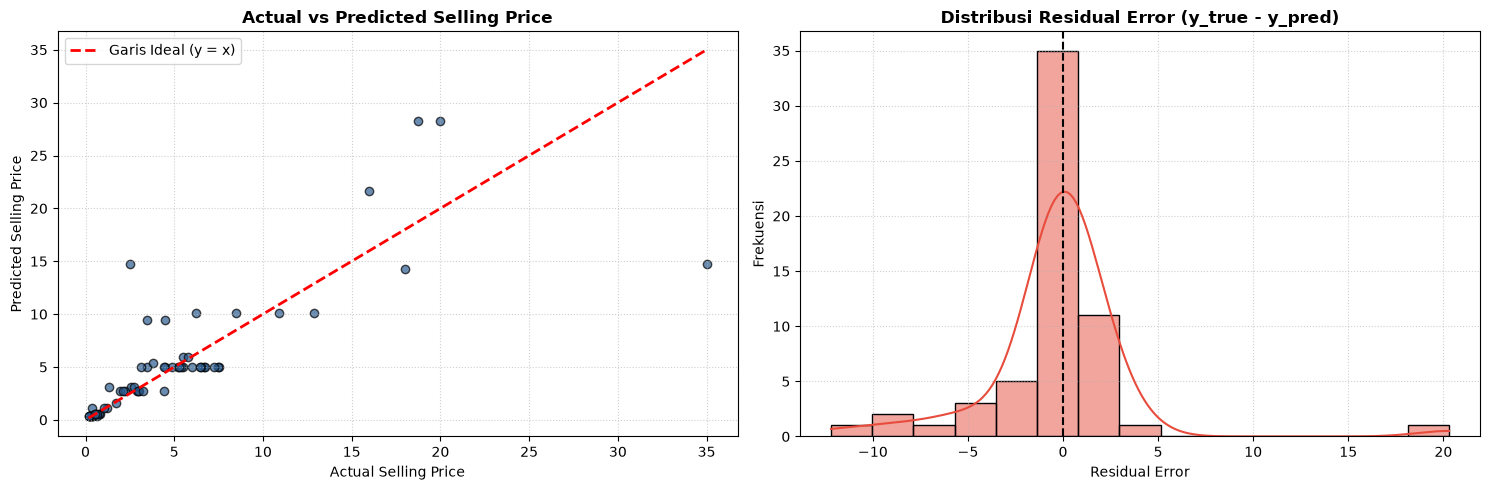

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(y_test, y_test_pred, color='#2b5c8f', edgecolors='k', alpha=0.7)
min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Garis Ideal (y = x)')
axes[0].set_title('Actual vs Predicted Selling Price', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Selling Price')
axes[0].set_ylabel('Predicted Selling Price')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

residuals = y_test.values - y_test_pred
sns.histplot(residuals, kde=True, ax=axes[1], color='#e74c3c', bins=15)
axes[1].axvline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title('Distribusi Residual Error (y_true - y_pred)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Residual Error')
axes[1].set_ylabel('Frekuensi')
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()